# Prediksi Biaya Asuransi Kesehatan
---
## 1. Business Understanding

### 1.1 Latar belakang, masalah, solusi
1. **Latar Belakang**: Sebuah perusahaan asuransi kesehatan ingin memprediksi estimasi biaya tagihan medis/klaim (charges) per pemegang polis berdasarkan profil demografi, kondisi tubuh, kebiasaan merokok, jumlah tanggungan, dan wilayah. Dengan model prediksi biaya yang akurat, perusahaan dapat menyusun penetapan premi yang lebih terukur, mendeteksi kelompok risiko biaya tinggi lebih awal, serta merancang program promotif-preventif yang tepat sasaran.
2. **Masalah**: Perusahaan asuranasi masih tidak memprediksi tagihan biaya yang menyebabkan biaya menjadi kurang akurat, dan penetapan premi yang kurang terukur.
3. **Solusi**: Membangun model *machine learning* dengan algoritma **LightGBM** untun memprediksi estimasi biaya tagihan secara otomatis berdasarkan profil demografi, kondisi tubuh, kebiasan merokok, jumlha tanggunngan, dan wilayah.

---
## 2. Data Preparation

### 2.1 Import library

In [252]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load dataset

In [253]:
df = pd.read_csv('insurance.csv', na_values=['NA', 'N/A', 'NaN', '', ' '])
df.columns = df.columns.str.strip()

### 2.3 Menampilkan data teratas dan data terbawah

In [254]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [255]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


### 2.4 Memeriksa informasi data

In [256]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


### 2.5 Memeriksa jumlah data, missing value, dan data duplikat

In [257]:
print(f'Jumlah data: {df.size}')

print(f'Jumlah missing value: {df.isnull().sum().sum()}')
print(f'--- missing value per kolom --- \n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'\nJumlah data duplikat: {df.duplicated().sum()}')

Jumlah data: 9366
Jumlah missing value: 0
--- missing value per kolom --- 
Series([], dtype: int64)

Jumlah data duplikat: 1


---
## 3. Explaratory Data Analysis (EDA)

### 3.1 Memeriksa deskripsi data

In [258]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### 3.2 Memeriksa outlier dengan IQR dan Z-Score

In [259]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
outliers = []

for col in numeric_cols:
    if col in numeric_cols:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        mean = df[col].mean()
        median = df[col].median()
        min = df[col].min()
        max = df[col].max()
        std = df[col].std()
        skew = df[col].skew()
        lower = q1 - (1.5 * iqr)
        upper = q3 + (1.5 * iqr)
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'standar deviasi': std,
            'kemiringan': skew,
            'min': min,
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': max,
            'batas bawah': lower,
            'batas atas': upper,
            'outlier (IQR)': outlier_iqr.shape[0],
            'outlier (Z-Score)': outlier_z.shape[0],
        })

pd.DataFrame(outliers)

,nama kolom,mean,standar deviasi,kemiringan,min,q1,median,q3,max,batas bawah,batas atas,outlier (IQR),outlier (Z-Score)
0,age,39.207025,14.049960,0.055673,18.0000,27.00000,39.000,51.000000,64.00000,-9.000000,87.000000,0,0
1,bmi,30.663397,6.098187,0.284047,15.9600,26.29625,30.400,34.693750,53.13000,13.700000,47.290000,9,4
2,children,1.094918,1.205493,0.938380,0.0000,0.00000,1.000,2.000000,5.00000,-3.000000,5.000000,0,18
3,charges,13270.422265,12110.011237,1.515880,1121.8739,4740.28715,9382.033,16639.912515,63770.42801,-13109.150897,34489.350562,139,7


### 3.3 Visualisasi outlier dengan boxplot

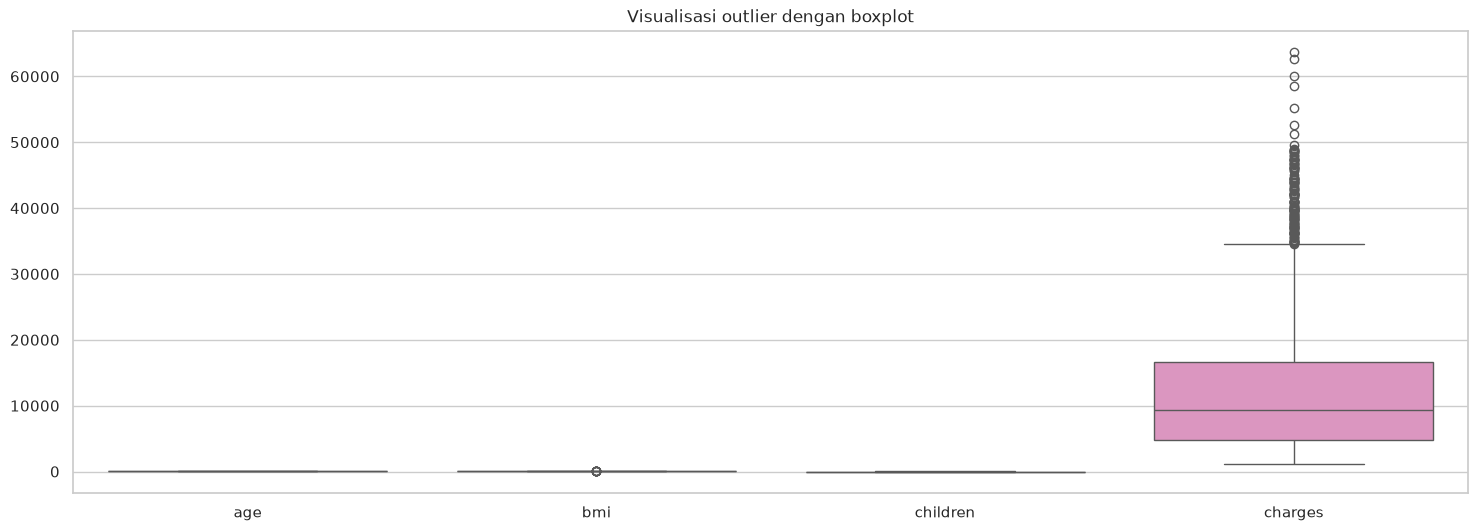

In [260]:
plt.figure(figsize=(18, 6))
sns.boxplot(df, palette='Set2')
plt.title('Visualisasi outlier dengan boxplot')
plt.show()

### 3.4 Visualisasi distribusi data

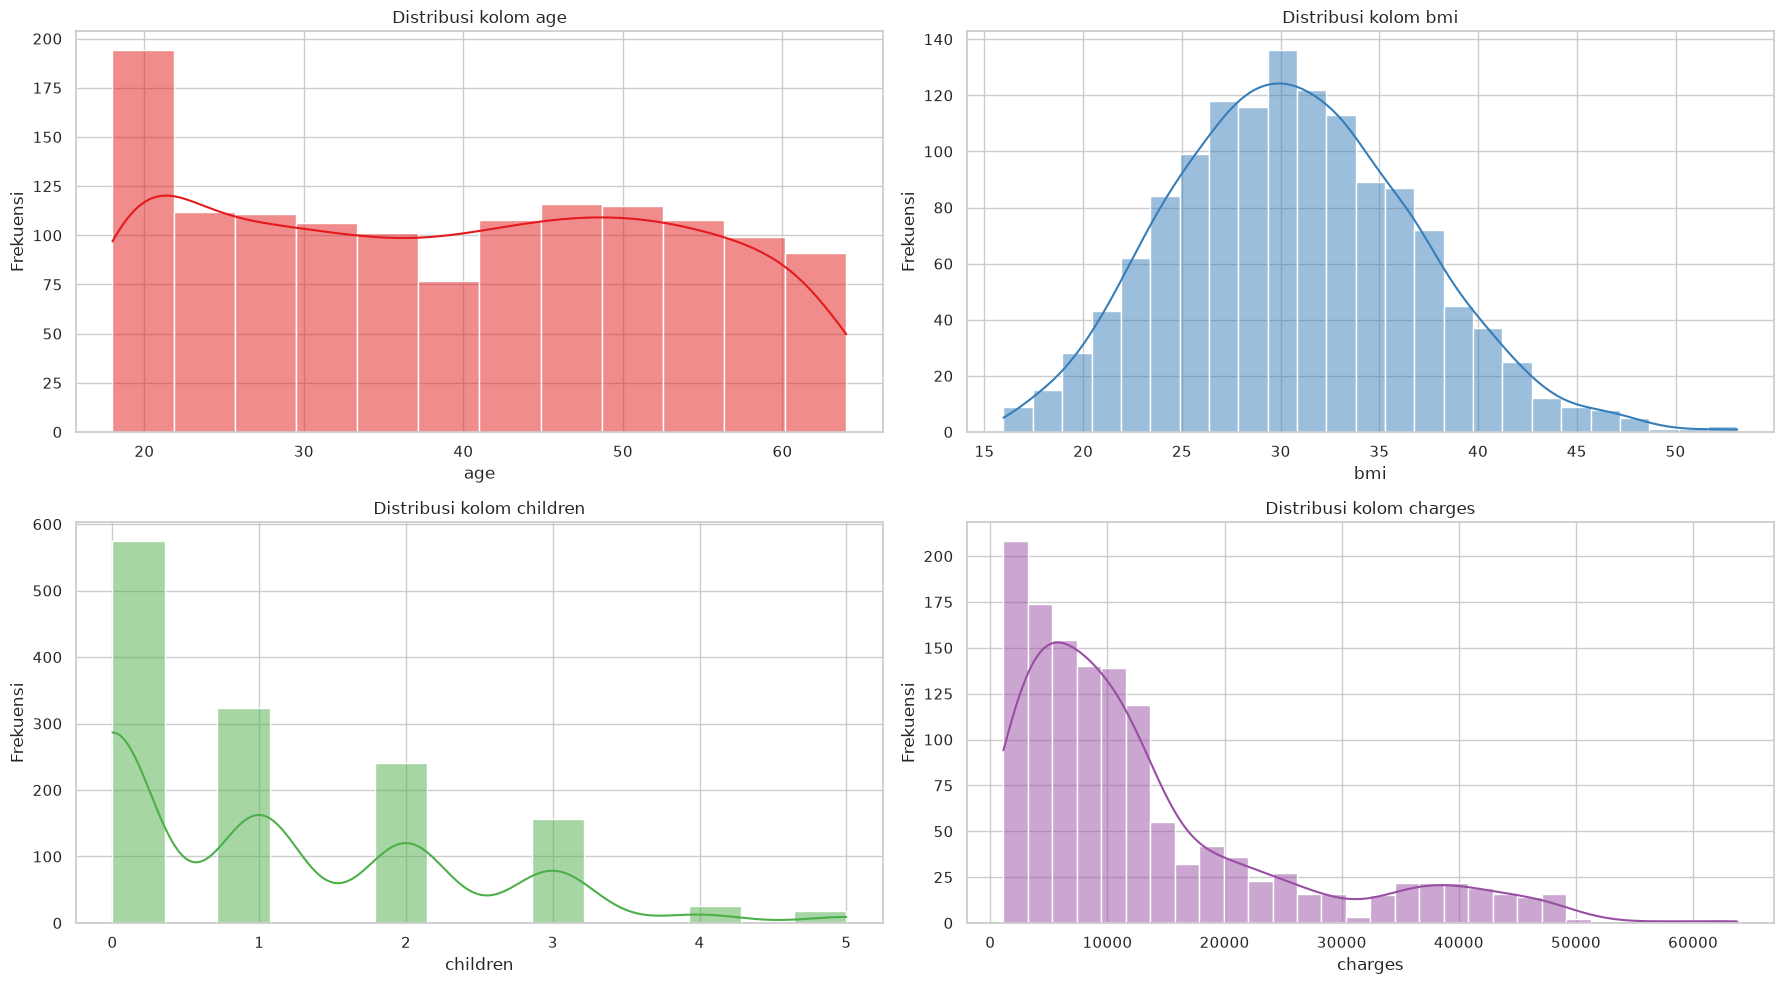

In [261]:
n_cols = 2
n_rows = int(len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()
sns.set_theme(style='whitegrid')
colors = sns.color_palette(palette='Set1', n_colors=len(numeric_cols))

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, kde=True, color=colors[i], ax=axes[i])
    axes[i].set_title(f'Distribusi kolom {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 3.5 Visualisasi Distribusi Kolom kategorikal

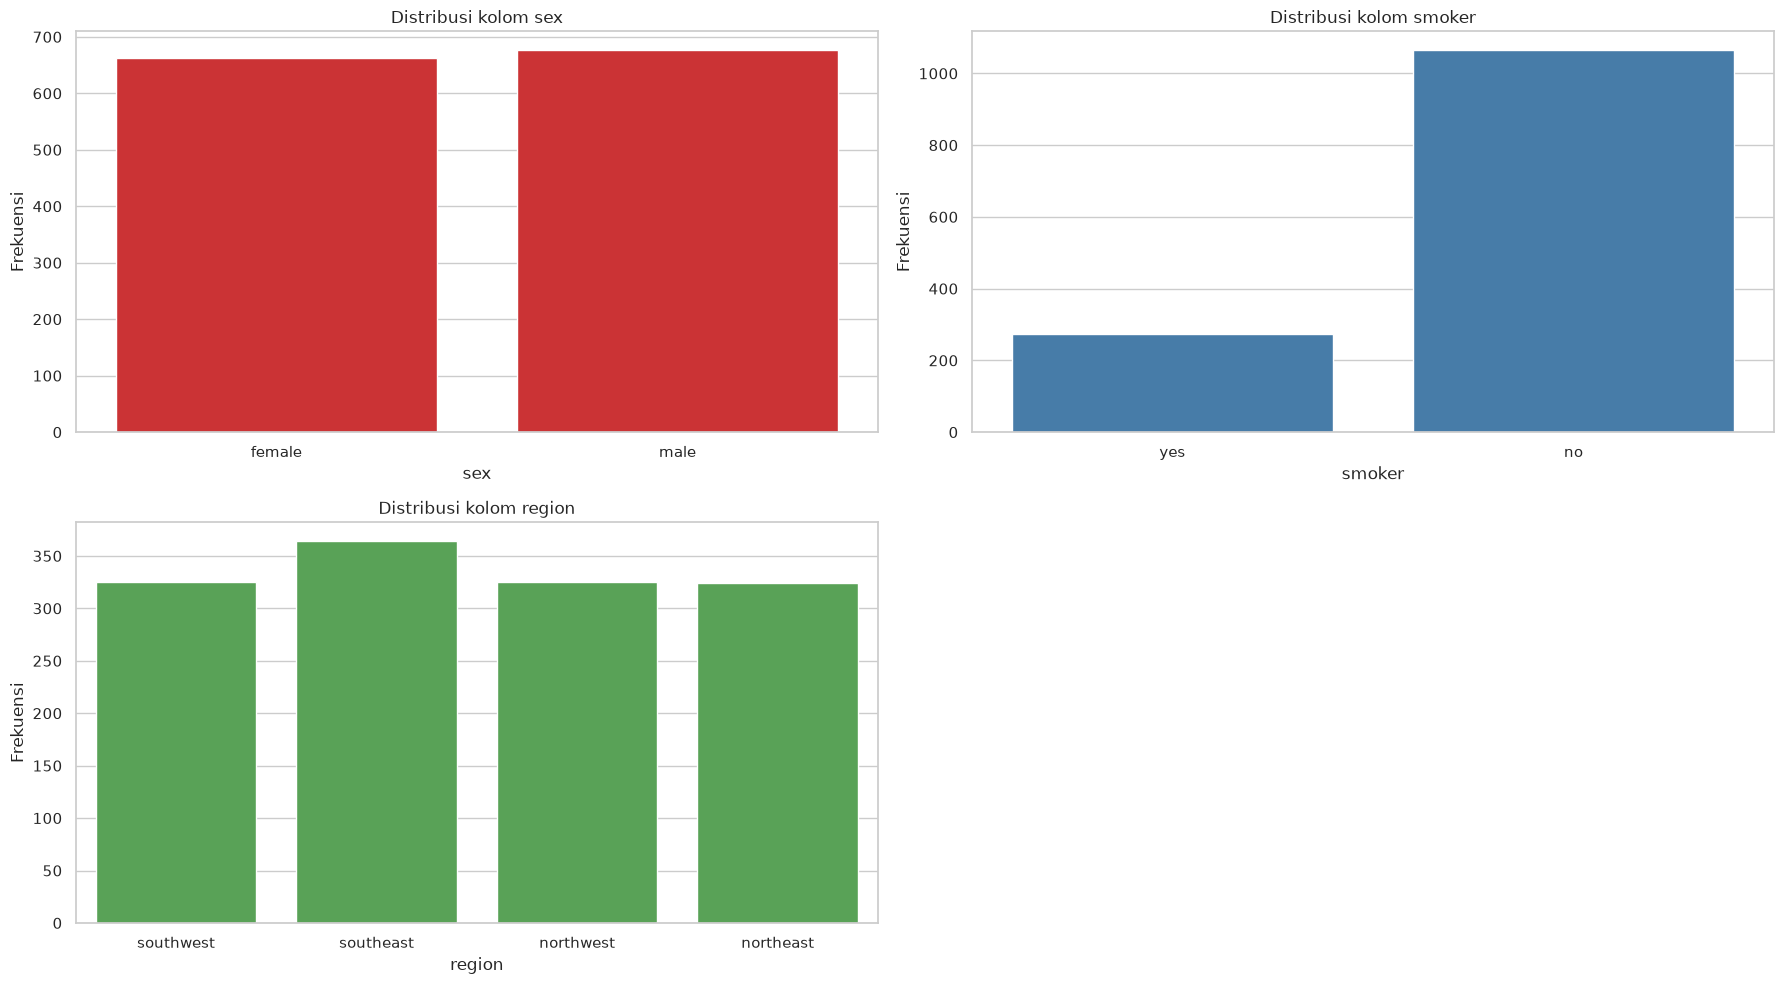

In [262]:
categorical_cols = df.select_dtypes(include=['str', 'object']).columns.tolist()
n_cols = 2
n_rows = int(len(categorical_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()
sns.set_theme(style='whitegrid')
colors = sns.color_palette(palette='Set1', n_colors=len(categorical_cols))

for i, col in enumerate(categorical_cols):
    sns.countplot(data=df, x=col, color=colors[i], ax=axes[i])
    axes[i].set_title(f'Distribusi kolom {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 3.6 Visualisasi korelasi antar kolom numerik

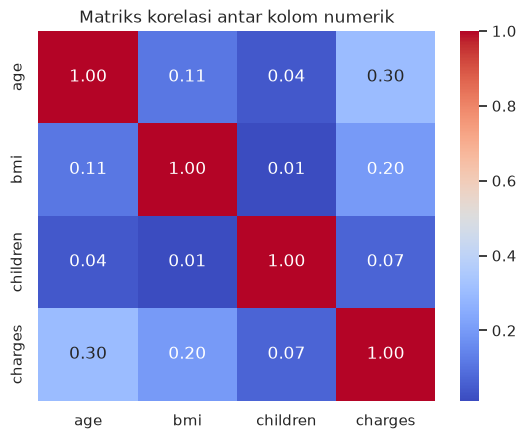

In [263]:
korelasi = df[numeric_cols].corr(method='pearson')
sns.heatmap(korelasi, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('Matriks korelasi antar kolom numerik')
plt.show()

---
## 4. Data Preprocessing

### 4.1 Memeriksa kembali missing value dan data duplikat

In [264]:
print(f'Jumlah missing value: {df.isnull().sum().sum()}')
print(f'--- missing value per kolom --- \n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'\nJumlah data duplikat: {df.duplicated().sum()}')

Jumlah missing value: 0
--- missing value per kolom --- 
Series([], dtype: int64)

Jumlah data duplikat: 1


### 4.2 Menghapus data duplikat

In [265]:
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(f'Sisa baris data: {df.shape[0]} Baris')

Sisa baris data: 1337 Baris


### 4.3 Memisah kolom fitur($X$) dan kolom target($y$)

In [266]:
X = df.drop(columns=['charges'])
y = df['charges']

print(f'Dimensi fitur (X): {X.shape[0]} Baris, {X.shape[1]} Kolom')
print(f'Dimensi target (y): {y.shape[0]} Baris')

Dimensi fitur (X): 1337 Baris, 6 Kolom
Dimensi target (y): 1337 Baris


### 4.4 Spliting data training dan data testing

In [267]:
np.random.seed(42)
random_idx = np.random.permutation(len(X))

batas = int(0.8 * len(X))

idx_train = random_idx[:batas]
idx_test = random_idx[batas:]

X_train = X.iloc[idx_train].copy().reset_index(drop=True)
X_test = X.iloc[idx_test].copy().reset_index(drop=True)
y_train = y.iloc[idx_train].reset_index(drop=True)
y_test = y.iloc[idx_test].reset_index(drop=True)

print(f'Jumlah baris data training: {X_train.shape[0]} Baris')
print(f'Jumlah baris data testing: {X_test.shape[0]} Baris')

Jumlah baris data training: 1069 Baris
Jumlah baris data testing: 268 Baris


### 4.5 Merubah kolom string menjadi kolom kategori

In [268]:
string = ['sex', 'smoker', 'region']
mapping_hasil = {}
for col in string:
    code, unique = pd.factorize(X_train[col])
    X_train[col] = code
    X_test[col] = pd.Categorical(X_test[col], categories=unique).codes
    mapping_hasil[col] = dict(enumerate(unique))

for col, mapping in mapping_hasil.items():
    print(f"Kolom '{col}': {mapping}")

Kolom 'sex': {0: 'male', 1: 'female'}
Kolom 'smoker': {0: 'no', 1: 'yes'}
Kolom 'region': {0: 'northeast', 1: 'southwest', 2: 'northwest', 3: 'southeast'}


### 4.6 Feature Scaling

In [269]:
list = ['age', 'bmi', 'children']

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()


for col in list:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    median = X_train[col].median()
    X_train_scaled[col] = (X_train[col] - median) / iqr
    X_test_scaled[col] = (X_test[col] - median) /iqr

X_train.describe()

,age,sex,bmi,children,smoker,region
count,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000
mean,39.256314,0.491113,30.713924,1.101029,0.205800,1.553789
std,14.003202,0.500155,6.117881,1.209005,0.404474,1.123530
min,18.000000,0.000000,15.960000,0.000000,0.000000,0.000000
25%,27.000000,0.000000,26.410000,0.000000,0.000000,1.000000
50%,39.000000,0.000000,30.495000,1.000000,0.000000,2.000000
75%,51.000000,1.000000,34.770000,2.000000,0.000000,3.000000
max,64.000000,1.000000,53.130000,5.000000,1.000000,3.000000


### 4.7 Visualisasi data setelah feature scaling

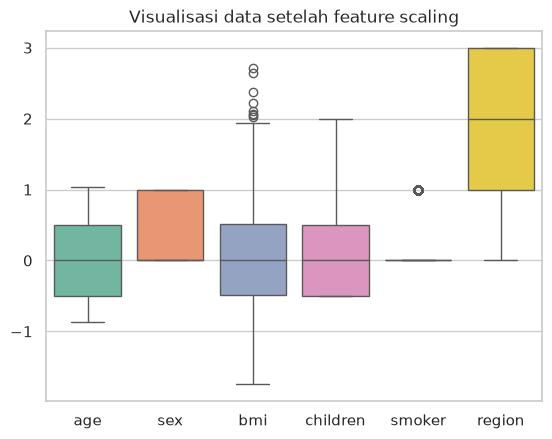

In [270]:
sns.boxplot(data=X_train_scaled, palette='Set2')
plt.title('Visualisasi data setelah feature scaling')
plt.show()